# M8: HCF 모세관 · 2코어 MCF 검증 보고서

**런타임 → 모두 실행**으로 재계산합니다. 저장된 결과도 바로 볼 수 있습니다.

HCF는 이상적 모세관 J0/Dirichlet 모델입니다. 실제 ARF/NANF의 누설 손실 검증은 포함하지 않습니다. MCF는 동일 원형 코어 2개의 약도파 스칼라 모델입니다. 오차율은 동일 모델의 독립 기준 해 대비 값이며, 실물 제품 대비 오차가 아닙니다.

[HCF 상세 보고서](https://github.com/kimheeseo/LSCNS/blob/main/COMSOL/waveoptics_m8/HCF_VALIDATION_REPORT.md) · [MCF 상세 보고서](https://github.com/kimheeseo/LSCNS/blob/main/COMSOL/waveoptics_m8/MCF_2CORE_VALIDATION_REPORT.md)

In [1]:
# 설치: Colab/Linux에서 Gmsh 공유 라이브러리가 필요합니다.
import sys,subprocess,importlib.util
try:
    import gmsh
except (ImportError,OSError):
    subprocess.check_call(['apt-get','update','-qq'])
    subprocess.check_call(['apt-get','install','-y','-qq','libglu1-mesa','libxft2','libxrender1','libxinerama1','libxcursor1'])
required=['numpy==2.3.5','scipy==1.17.0','matplotlib==3.10.8','scikit-fem==12.0.2','gmsh==4.15.2']
# 이미 검증된 버전이면 설치를 생략합니다.
from importlib.metadata import version,PackageNotFoundError
needs_install=False
for requirement in required:
    name,wanted=requirement.split('==')
    try:needs_install |= version(name)!=wanted
    except PackageNotFoundError:needs_install=True
if needs_install:
    subprocess.check_call([sys.executable,'-m','pip','install','-q',*required])
    print('설치 완료. 기존에 다른 버전을 import했다면 런타임을 재시작한 뒤 모두 실행하십시오.')
else: print('검증된 의존성 버전 확인 완료')

검증된 의존성 버전 확인 완료


## 입력값

파장은 µm, 코어 반경·간격·메시·해석영역은 µm입니다. 간격은 코어 중심 사이 거리입니다. Δn는 core−cladding입니다. 공기 굴절률은 파장에 대해 일정하다고 가정합니다.

MCF는 단일 코어 V<2.405, 동일 코어, 비중첩 구조를 사용합니다. 아래 설정은 보고서 검증 예입니다. 새 조건에서 판정 실패가 나오면 실패 수치와 수렴 결과를 함께 확인하십시오.

In [2]:
#@title 기본 설계 입력
wavelength_um = 1.55 #@param {type:"number"}
core_radius_um = 4.1 #@param {type:"number"}
delta_n = 0.005 #@param {type:"number"}
pitch_um = 16.0 #@param {type:"number"}
hcf_radius_um = 15.0 #@param {type:"number"}
n_air = 1.00027 #@param {type:"number"}
CONFIG=dict(wavelength_um=wavelength_um,core_radius_um=core_radius_um,delta_n=delta_n,
            pitch_um=pitch_um,hcf_radius_um=hcf_radius_um,n_air=n_air,
            mesh_sizes_um=[1.0,0.7,0.45,0.3],halfwidth_um=40.0,
            domain_halfwidths_um=[28.0,32.0,40.0],pitches_um=[12.0,16.0,20.0,24.0],
            hcf_elements=[40,80,160,320,640])
print(CONFIG)

{'wavelength_um': 1.55, 'core_radius_um': 4.1, 'delta_n': 0.005, 'pitch_um': 16.0, 'hcf_radius_um': 15.0, 'n_air': 1.00027, 'mesh_sizes_um': [1.0, 0.7, 0.45, 0.3], 'halfwidth_um': 40.0, 'domain_halfwidths_um': [28.0, 32.0, 40.0], 'pitches_um': [12.0, 16.0, 20.0, 24.0], 'hcf_elements': [40, 80, 160, 320, 640]}


## 내장 해석 엔진

아래 셀은 저장소의 실제 소스를 내장합니다. HCF 방사형 FEM과 Bessel 기준, MCF 곡선 P2 FEM과 독립 무한영역 원통함수 정합을 별도로 계산합니다. 외부 저장소를 런타임에 내려받지 않습니다.

In [3]:
# SOURCE: waveoptics_m7/src/fiber_modes.py
"""M7 optical fiber 2D scalar P1 FEM, independent circular LP01 Bessel validator.
Units in micrometers. Weak-guidance modes only, no vector PML / confinement loss.
"""

import numpy as np

from dataclasses import dataclass

from scipy.sparse import coo_matrix

from scipy.sparse.linalg import eigsh

from scipy.special import j0,j1,k0 as K0,k1 as K1

from scipy.optimize import brentq

from scipy.integrate import quad

C0=299792458.

SB=(.6961663,.4079426,.8974794)

SC=(.0684043**2,.1162414**2,9.896161**2)

def silica_index(w):
 w=float(w)
 if not np.isfinite(w) or not .21<w<3.7:raise ValueError("Sellmeier domain")
 return float(np.sqrt(1+sum(b*w*w/(w*w-c) for b,c in zip(SB,SC))))

@dataclass(frozen=True)
class Fiber:
 wavelength_um:float=1.55
 radius_um:float=4.1
 delta_n:float=.005
 domain_halfwidth_um:float=18.
 n_cladding:float|None=None
 def __post_init__(self):
  for name in ('wavelength_um','radius_um','delta_n','domain_halfwidth_um'):
   value=getattr(self,name)
   if not np.isfinite(value) or value<=0:raise ValueError(name+' must be positive and finite')
  if self.domain_halfwidth_um<=2*self.radius_um:raise ValueError('domain halfwidth must exceed twice core radius')
  if self.n_cladding is not None and (not np.isfinite(self.n_cladding) or self.n_cladding<=0):
   raise ValueError('n_cladding must be positive and finite')
  # Validate the dispersion model immediately, before assembly.
  if self.n_cladding is None:silica_index(self.wavelength_um)
 @property
 def clad(self):return silica_index(self.wavelength_um) if self.n_cladding is None else self.n_cladding
 @property
 def core(self):return self.clad+self.delta_n
 @property
 def v(self):return 2*np.pi*self.radius_um/self.wavelength_um*np.sqrt(self.core**2-self.clad**2)

def lp01_analytic(f):
 v=f.v
 if not 0<v<2.404825557695772:raise ValueError("LP01 oracle limited to V<2.405")
 def eq(u):
  w=np.sqrt(v*v-u*u)
  return u*j1(u)/j0(u)-w*K1(w)/K0(w)
 u=brentq(eq,max(v*1e-6,1e-8),v*(1-1e-10),xtol=2e-13)
 w=np.sqrt(v*v-u*u)
 return dict(V=float(v),u=float(u),w=float(w),n_eff=float(np.sqrt((2*np.pi*f.core/f.wavelength_um)**2-(u/f.radius_um)**2)*f.wavelength_um/(2*np.pi)))

def radial_lp01_aeff(f):
 """Adaptive infinite-domain LP01 integrals, independent of FEM box size."""
 a=lp01_analytic(f);u,w=a['u'],a['w'];radius=f.radius_um
 def shape(t):
  return j0(u*t)/j0(u) if t<=1 else K0(w*t)/K0(w)
 def integrate(power,moment):
  fun=lambda t:shape(t)**power*t**moment
  return quad(fun,0,1,epsabs=1e-11,epsrel=1e-10)[0]+quad(fun,1,np.inf,epsabs=1e-11,epsrel=1e-10)[0]
 total=2*np.pi*radius**2*integrate(2,1)
 four=2*np.pi*radius**2*integrate(4,1)
 mom=2*np.pi*radius**4*integrate(2,3)/total
 return dict(Aeff_um2=float(total**2/four),MFD_2nd_um=float(2*np.sqrt(2*mom)))

def grid(n,h):
 if not isinstance(n,(int,np.integer)) or isinstance(n,bool) or n<15 or n%2!=1:raise ValueError("odd mesh count>=15")
 if not np.isfinite(h) or h<=0:raise ValueError("positive finite halfwidth")
 xy=np.stack(np.meshgrid(np.linspace(-h,h,n),np.linspace(-h,h,n),indexing='xy'),-1).reshape(-1,2)
 i,j=np.meshgrid(np.arange(n-1),np.arange(n-1),indexing='xy');p=(j*n+i).ravel()
 tris=np.concatenate([np.stack([p,p+1,p+n+1],1),np.stack([p,p+n+1,p+n],1)]).astype(int)
 free=np.flatnonzero((np.abs(xy[:,0])<h-1e-9)&(np.abs(xy[:,1])<h-1e-9))
 return xy,tris,free

def assemble_fem(xy,tri,index):
 p=xy[tri];dx=p[:,1,0]-p[:,0,0];dy=p[:,1,1]-p[:,0,1];ex=p[:,2,0]-p[:,0,0];ey=p[:,2,1]-p[:,0,1]
 det=dx*ey-dy*ex
 if np.any(np.abs(det)<1e-14):raise ValueError("degenerate triangle")
 area=np.abs(det)/2
 gx=np.stack([p[:,1,1]-p[:,2,1],p[:,2,1]-p[:,0,1],p[:,0,1]-p[:,1,1]],1)/det[:,None]
 gy=np.stack([p[:,2,0]-p[:,1,0],p[:,0,0]-p[:,2,0],p[:,1,0]-p[:,0,0]],1)/det[:,None]
 K=area[:,None,None]*(gx[:,:,None]*gx[:,None,:]+gy[:,:,None]*gy[:,None,:])
 b=np.ones((3,3));np.fill_diagonal(b,2)
 M=area[:,None,None]*b[None,:,:]/12
 ni=np.asarray(index(p.mean(1)),float)
 if len(ni)!=len(area) or np.any(ni<=0):raise ValueError("invalid index")
 N=M*ni[:,None,None]**2
 rows=np.broadcast_to(tri[:,:,None],(len(tri),3,3)).ravel()
 cols=np.broadcast_to(tri[:,None,:],(len(tri),3,3)).ravel()
 def csr(v):return coo_matrix((v.ravel(),(rows,cols)),shape=(len(xy),len(xy))).tocsr()
 return csr(K),csr(M),csr(N)

def solve_modes(f,n=81,cores=None,modes=2):
 if f.radius_um<=0 or f.delta_n<=0 or f.domain_halfwidth_um<=f.radius_um*2:raise ValueError("invalid fiber")
 centers=[(0.,0.)] if cores is None else list(cores)
 c=np.asarray(centers,float)
 if c.ndim!=2 or c.shape[1]!=2 or not len(c) or not np.all(np.isfinite(c)):
  raise ValueError('cores must be a nonempty finite sequence of (x,y) pairs')
 if np.any(np.abs(c)+f.radius_um>=f.domain_halfwidth_um):raise ValueError('core intersects outer boundary')
 if not isinstance(modes,(int,np.integer)) or isinstance(modes,bool) or modes<1:
  raise ValueError('modes must be a positive integer')
 xy,tri,free=grid(n,f.domain_halfwidth_um)
 def index(points):
  r2=np.full(len(points),np.inf)
  for xx,yy in centers:r2=np.minimum(r2,(points[:,0]-xx)**2+(points[:,1]-yy)**2)
  return np.where(r2<=f.radius_um**2,f.core,f.clad)
 K,M,N=assemble_fem(xy,tri,index);k0=2*np.pi/f.wavelength_um;A=(k0*k0*N-K)[free][:,free];MM=M[free][:,free]
 if modes>=len(free):raise ValueError('too many requested modes')
 vals,vectors=eigsh(A,k=modes,M=MM,sigma=(k0*f.core)**2+.02,which='LM',tol=1e-10,v0=np.random.default_rng(0).normal(size=len(free)))
 order=np.argsort(vals)[::-1];vals=vals[order];vectors=vectors[:,order]
 fields=np.zeros((len(xy),modes));fields[free,:]=vectors
 neff=np.sqrt(np.maximum(0,vals))/k0
 resid=[float(np.linalg.norm(A@vectors[:,i]-vals[i]*(MM@vectors[:,i]))/np.linalg.norm(vals[i]*(MM@vectors[:,i]))) for i in range(modes)]
 return dict(fiber=f,n=n,xy=xy,triangles=tri,free=free,mass=M,neff=neff,fields=fields,guided=(neff>f.clad)&(neff<f.core),residuals=resid,cores=centers)

def scalar_metrics(sol,k=0):
 """Integrate the P1 field with degree-5 triangle quadrature (no nodal lumping).

 MFD_2nd is a centered scalar second-moment diameter, not Petermann-II MFD.
 """
 if not isinstance(k,(int,np.integer)) or not 0<=k<sol['fields'].shape[1]:raise ValueError('invalid mode index')
 # Dunavant 7-point rule, weights sum to one; exact through degree five.
 b=np.array([[1/3,1/3,1/3],
  [.059715871789770,.470142064105115,.470142064105115],
  [.470142064105115,.059715871789770,.470142064105115],
  [.470142064105115,.470142064105115,.059715871789770],
  [.797426985353087,.101286507323456,.101286507323456],
  [.101286507323456,.797426985353087,.101286507323456],
  [.101286507323456,.101286507323456,.797426985353087]])
 weights=np.array([.225,.132394152788506,.132394152788506,.132394152788506,
                   .125939180544827,.125939180544827,.125939180544827])
 tri=sol['triangles'];xyz=sol['xy'][tri];p=sol['fields'][tri,k]
 area=np.abs((xyz[:,1,0]-xyz[:,0,0])*(xyz[:,2,1]-xyz[:,0,1])-
             (xyz[:,2,0]-xyz[:,0,0])*(xyz[:,1,1]-xyz[:,0,1]))/2
 intensity=np.abs(p@b.T)**2;points=np.einsum('qi,tij->tqj',b,xyz)
 wt=area[:,None]*weights
 power=float(np.sum(wt*intensity));four=float(np.sum(wt*intensity**2))
 if not np.isfinite(power) or power<=0:raise ValueError('mode has zero or nonfinite power')
 center=np.sum(wt[:,:,None]*intensity[:,:,None]*points,axis=(0,1))/power
 r2=np.sum((points-center)**2,axis=2);moment=np.sum(wt*intensity*r2)/power
 return dict(n_eff=float(sol['neff'][k]),Aeff_um2=power**2/four,
             MFD_2nd_um=float(2*np.sqrt(2*moment)),residual=float(sol['residuals'][k]),
             centroid_um=center.tolist(),power_integral=power)

def dispersion_lp01(w=1.55,step=.003):
 if not np.isfinite(w) or not np.isfinite(step) or step<=0:raise ValueError('finite wavelength and positive step required')
 def ne(x):return lp01_analytic(Fiber(wavelength_um=float(x)))['n_eff']
 h=step;d2=(-ne(w+2*h)+16*ne(w+h)-30*ne(w)+16*ne(w-h)-ne(w-2*h))/(12*h*h)
 return float(-(w/C0)*1e12*d2)

# SOURCE: waveoptics_m8/src/multipole_reference.py
"""Independent scalar two-circle boundary matching in an infinite cladding.

Own-core exterior = sum b_m K_m(w*r)/K_m(w*a) cos(m*theta).
Interior logarithmic radial derivative = q*J_m'(q*a)/J_m(q*a).
Fourier-project continuity of the normal derivative on one circle, after
eliminating the interior amplitude using continuity of the field.
Reflection: b_right,m = parity*(-1)**m*b_left,m. Only y-even modes.
No FEM mesh, finite box, vector polarization, bending or random coupling.
"""

import numpy as np

from scipy.special import jv,jvp,kv,kvp

from scipy.optimize import brentq

def validate(fiber, pitch_um):
    if not np.isfinite(pitch_um) or pitch_um <= 2*fiber.radius_um:
        raise ValueError('pitch must exceed two core radii')
    if not 0 < fiber.v < 2.404825557695773:
        raise ValueError('benchmark restricted to isolated-core V<2.405')

def boundary_matrix(neff, fiber, pitch_um=16., order=6, parity=1, samples=256):
    validate(fiber,pitch_um)
    if not isinstance(order,(int,np.integer)) or isinstance(order,bool) or not 0 <= order <= 20:
        raise ValueError('multipole order must be integer 0..20')
    if parity not in (-1,1) or samples < 8*(order+1):
        raise ValueError('invalid parity or angular sampling')
    if not fiber.clad < neff < fiber.core:
        raise ValueError('reference root must be guided')
    a=fiber.radius_um; k=2*np.pi/fiber.wavelength_um
    q=k*np.sqrt(fiber.core**2-neff**2); w=k*np.sqrt(neff**2-fiber.clad**2)
    m=np.arange(order+1); theta=2*np.pi*np.arange(samples)/samples
    ct,st=np.cos(theta),np.sin(theta)
    # Left circle centered at 0; right circle at (+pitch, 0).
    dx=a*ct-pitch_um; dy=a*st; rr=np.hypot(dx,dy); angle=np.arctan2(dy,dx)
    dr=(dx*ct+dy*st)/rr
    dt=(-dy*ct+dx*st)/rr**2
    cos=np.cos(theta[:,None]*m)
    other=kv(m,w*rr[:,None])/kv(m,w*a)*np.cos(angle[:,None]*m)
    other_derivative=(w*kvp(m,w*rr[:,None])/kv(m,w*a)*dr[:,None]*np.cos(angle[:,None]*m)
                      -kv(m,w*rr[:,None])/kv(m,w*a)*m*dt[:,None]*np.sin(angle[:,None]*m))
    projection=cos.T/samples
    projection[1:]*=2
    log_derivative=q*jvp(m,q*a)/jv(m,q*a)
    diagonal=w*kvp(m,w*a)/kv(m,w*a)-log_derivative
    matrix=np.diag(diagonal)+(projection@other_derivative-log_derivative[:,None]*(projection@other))*(parity*(-1.)**m)
    # Row scaling improves determinant conditioning and leaves its roots intact.
    return matrix/(1+np.abs(log_derivative[:,None]))

def solve_reference(fiber, pitch_um=16., order=6, samples=256):
    validate(fiber,pitch_um)
    roots=[]; singular=[]
    for parity in (1,-1):
        def fun(n):return float(np.linalg.det(boundary_matrix(n,fiber,pitch_um,order,parity,samples)))
        grid=np.linspace(fiber.clad+fiber.delta_n*1e-5, fiber.core-fiber.delta_n*1e-5,120)
        values=[fun(n) for n in grid]
        brackets=[(x,y) for x,y,u,v in zip(grid[:-1],grid[1:],values[:-1],values[1:]) if u*v<0]
        if len(brackets)!=1:
            raise RuntimeError(f'expected one y-even root for parity {parity}, found {len(brackets)}')
        n=brentq(fun,*brackets[0],xtol=5e-15,rtol=1e-15)
        roots.append(float(n))
        sv=np.linalg.svd(boundary_matrix(n,fiber,pitch_um,order,parity,samples),compute_uv=False)
        singular.append(float(sv[-1]/sv[0]))
    split=roots[0]-roots[1]
    if split<=0:raise RuntimeError('unresolved even/odd splitting')
    return dict(n_even=roots[0],n_odd=roots[1],index_split=split,
                coupling_length_mm=fiber.wavelength_um/(2*split)/1000,
                order=order,angular_samples=samples,boundary_relative_singular=singular,
                reference='independent scalar Fourier-Bessel matching; infinite cladding')

# SOURCE: waveoptics_m8/src/capillary_fem.py
"""Independent radial P1 eigenproblem for the ideal scalar hollow capillary.

-(r psi')'=kt^2*r*psi, regular at r=0, psi(R)=0.
This verifies the J0/Dirichlet baseline only, not ARF/NANF glass-wall physics.
"""

import numpy as np

from scipy.sparse import coo_matrix

from scipy.sparse.linalg import eigsh

from numpy.polynomial.legendre import leggauss

C0=299792458.

def solve_capillary(wavelength_um=1.55,radius_um=15.,n_air=1.00027,elements=320,return_field=False):
    if not isinstance(elements,(int,np.integer)) or isinstance(elements,bool) or elements<4:
        raise ValueError('elements must be integer >=4')
    if not np.all(np.isfinite([wavelength_um,radius_um,n_air])) or wavelength_um<=0 or radius_um<=0 or n_air<1:
        raise ValueError('invalid capillary parameters')
    r=np.linspace(0,radius_um,elements+1);h=np.diff(r)
    x,w=leggauss(4);t=(x+1)/2;phi=np.stack([1-t,t],1)
    rq=r[:-1,None]+h[:,None]*t;weights=h[:,None]*w/2
    mass=np.einsum('eq,qi,qj->eij',weights*rq,phi,phi)
    stiff=((r[1:]**2-r[:-1]**2)/(2*h**2))[:,None,None]*np.array([[1.,-1.],[-1.,1.]])
    edges=np.stack([np.arange(elements),np.arange(elements)+1],1)
    rows=np.broadcast_to(edges[:,:,None],mass.shape).ravel();cols=np.broadcast_to(edges[:,None,:],mass.shape).ravel()
    def mat(v):return coo_matrix((v.ravel(),(rows,cols)),shape=(elements+1,elements+1)).tocsr()[:-1,:-1]
    K,M=mat(stiff),mat(mass)
    vals,vec=eigsh(K,k=1,M=M,sigma=0,which='LM',tol=1e-12,v0=np.ones(elements))
    kt2=float(vals[0]);v=vec[:,0];field=np.r_[v,0.]
    if field[0]<0:field=-field
    q=kt2/(2*np.pi)**2;z=n_air*n_air-q*wavelength_um**2
    if z<=0:raise ValueError('outside capillary propagation regime')
    ne=np.sqrt(z);D=wavelength_um/C0*1e12*q*n_air**2/ne**3
    amp=field[edges]@phi.T;wt=2*np.pi*weights*rq;power=np.sum(wt*amp**2)
    result=dict(elements=elements,radial_step_um=radius_um/elements,wavelength_um=wavelength_um,
                radius_um=radius_um,n_air=n_air,transverse_kt2_per_um2=kt2,
                n_eff=float(ne),D_ps_nm_km=float(D),Aeff_um2=float(power**2/np.sum(wt*amp**4)),
                residual=float(np.linalg.norm(K@v-kt2*(M@v))/np.linalg.norm(kt2*(M@v))))
    if return_field:result.update(radius=r,field=field/np.sqrt(power))
    return result

# SOURCE: waveoptics_m8/src/conforming_mcf.py
"""Curved P2 scalar FEM for identical, straight, lossless two-core fibers.
Quarter-domain parity constraints avoid mesh asymmetry contaminating splitting.
Core interfaces are Gmsh arcs; P2 edge midpoints are projected onto circles.
"""

import numpy as np

from scipy.sparse.linalg import eigsh

from skfem import MeshTri,MeshTri2,Basis,ElementTriP2,BilinearForm,asm

from skfem.helpers import dot,grad

def build_mesh(fiber,pitch_um=16.,halfwidth_um=32.,mesh_size_um=.6):
    import gmsh
    validate(fiber,pitch_um)
    if not np.isfinite(halfwidth_um) or halfwidth_um <= pitch_um/2+2*fiber.radius_um:
        raise ValueError('halfwidth must leave at least one core radius of cladding')
    if not np.isfinite(mesh_size_um) or mesh_size_um<=0 or mesh_size_um>fiber.radius_um:
        raise ValueError('mesh size must be positive and <= core radius')
    if gmsh.isInitialized():raise RuntimeError('Gmsh already initialized: finish the existing model first')
    gmsh.initialize()
    try:
        gmsh.option.setNumber('General.Terminal',0)
        gmsh.option.setNumber('General.NumThreads',1)
        gmsh.model.add('symmetric_two_core')
        geo=gmsh.model.geo; a=fiber.radius_um;c=pitch_um/2;L=halfwidth_um;h=mesh_size_um
        def p(x,y):return geo.addPoint(x,y,0,h)
        bl,br,tr,tl=p(0,0),p(L,0),p(L,L),p(0,L)
        left,right,top,center=p(c-a,0),p(c+a,0),p(c,a),p(c,0)
        arc1=geo.addCircleArc(right,center,top);arc2=geo.addCircleArc(top,center,left)
        diameter=geo.addLine(left,right)
        core=geo.addPlaneSurface([geo.addCurveLoop([diameter,arc1,arc2])])
        lines=[geo.addLine(bl,left),geo.addLine(right,br),geo.addLine(br,tr),geo.addLine(tr,tl),geo.addLine(tl,bl)]
        clad=geo.addPlaneSurface([geo.addCurveLoop([lines[0],-arc2,-arc1,*lines[1:]])])
        geo.synchronize()
        gmsh.option.setNumber('Mesh.MeshSizeMin',h)
        gmsh.option.setNumber('Mesh.MeshSizeMax',h)
        gmsh.option.setNumber('Mesh.Algorithm',6)
        gmsh.model.mesh.generate(2)
        tags,coords,_=gmsh.model.mesh.getNodes();coords=np.asarray(coords).reshape(-1,3)[:,:2]
        lookup={int(t):i for i,t in enumerate(tags)}
        tri=[];is_core=[]
        for surface,inside in ((core,True),(clad,False)):
            types,_,nodes=gmsh.model.mesh.getElements(2,surface)
            for typ,nod in zip(types,nodes):
                if typ!=2:raise RuntimeError('expected linear triangles')
                t=np.array([lookup[int(x)] for x in nod]).reshape(-1,3)
                tri.extend(t);is_core.extend([inside]*len(t))
        # Drop unused geometric center node.
        tri=np.asarray(tri); used=np.unique(tri); remap=np.full(len(coords),-1);remap[used]=np.arange(len(used))
        linear=MeshTri(np.ascontiguousarray(coords[used].T),np.ascontiguousarray(remap[tri].T))
        mesh=MeshTri2.from_mesh(linear)
        # P2 internal interface edges are not exterior boundary facets.
        ids=mesh.facets
        r=np.hypot(linear.p[0]-c,linear.p[1])
        curved=np.flatnonzero(np.all(np.abs(r[ids]-a)<1e-8,axis=0))
        mid=Basis(mesh,ElementTriP2()).dofs.facet_dofs[0,curved]
        vector=mesh.doflocs[:,mid]-np.array([[c],[0.]])
        mesh.doflocs[:,mid]=np.array([[c],[0.]])+a*vector/np.linalg.norm(vector,axis=0)
        return mesh,np.array(is_core,dtype=bool)
    finally:gmsh.finalize()

@BilinearForm
def stiffness(u,v,w):return dot(grad(u),grad(v))

@BilinearForm
def mass(u,v,w):return u*v

@BilinearForm
def weighted_mass(u,v,w):return w.n2*u*v

def solve_conforming(fiber,pitch_um=16.,halfwidth_um=32.,mesh_size_um=.6,return_fields=False):
    mesh,inside=build_mesh(fiber,pitch_um,halfwidth_um,mesh_size_um)
    basis=Basis(mesh,ElementTriP2(),intorder=8)
    k=2*np.pi/fiber.wavelength_um
    K=asm(stiffness,basis);M=asm(mass,basis)
    n2=np.where(inside,fiber.core**2,fiber.clad**2)[:,None]*np.ones_like(basis.dx)
    N=asm(weighted_mass,basis,n2=n2);A=k*k*N-K
    x,y=basis.doflocs;L=halfwidth_um
    outer=np.isclose(x,L,atol=1e-9)|np.isclose(y,L,atol=1e-9)
    roots=[];residuals=[];fields=[]
    for parity in (1,-1):
        fixed=outer | ((np.isclose(x,0,atol=1e-9)) if parity==-1 else False)
        free=np.flatnonzero(~fixed);AA=A[free][:,free];MM=M[free][:,free]
        val,vec=eigsh(AA,k=1,M=MM,sigma=(k*fiber.core)**2,which='LM',tol=2e-12,v0=np.ones(len(free)))
        q=vec[:,0];beta2=float(val[0]);n=np.sqrt(beta2)/k
        roots.append(float(n));residuals.append(float(np.linalg.norm(AA@q-beta2*(MM@q))/np.linalg.norm(beta2*(MM@q))))
        full=np.zeros(basis.N);full[free]=q
        if np.sum(full)<0:full=-full
        fields.append(full)
    if not fiber.clad<roots[1]<roots[0]<fiber.core:raise RuntimeError('two guided parity modes not resolved')
    split=roots[0]-roots[1]
    result=dict(n_even=roots[0],n_odd=roots[1],index_split=split,
                coupling_length_mm=fiber.wavelength_um/(2*split)/1000,
                kappa_per_m=np.pi*split/(fiber.wavelength_um*1e-6),
                residuals=residuals,quarter_dofs=int(basis.N),quarter_elements=int(mesh.nelements),
                mesh_size_um=mesh_size_um,halfwidth_um=halfwidth_um,pitch_um=pitch_um,
                method='curved P2 scalar FEM; x/y parity quarter domain')
    if return_fields:result.update(mesh=mesh,basis=basis,fields=np.array(fields))
    return result

def coherent_transfer(length_m,coupling_length_mm):
    """Lossless identical two-mode model: P2=sin^2(pi*z/(2*Lc)).

    This is deterministic coherent transfer, not measured/random cable XT.
    """
    z=np.asarray(length_m,float)
    if np.any(~np.isfinite(z)) or np.any(z<0) or not np.isfinite(coupling_length_mm) or coupling_length_mm<=0:
        raise ValueError('finite nonnegative length and positive coupling length required')
    p2=np.sin(np.pi*z/(2*coupling_length_mm*1e-3))**2
    return dict(P1=1-p2,P2=p2)

# SOURCE: waveoptics_m8/src/mcf_hcf.py
U01=2.404825557695773

def solve_two_core(separation_um=16.,n=101,halfwidth_um=27.,*,fiber=None):
 from dataclasses import replace
 f=Fiber(domain_halfwidth_um=halfwidth_um) if fiber is None else replace(fiber,domain_halfwidth_um=halfwidth_um)
 if not np.all(np.isfinite([separation_um,halfwidth_um])) or separation_um<=2*f.radius_um or halfwidth_um<=separation_um/2+2*f.radius_um:raise ValueError("invalid 2-core cross section")
 sol=solve_modes(f,n,cores=[(-separation_um/2,0),(separation_um/2,0)],modes=2)
 if not all(sol['guided']):raise RuntimeError("two modes not guided")
 even,odd=map(float,sol['neff']);split=even-odd
 parity=[]
 for k in range(2):
  q=sol['fields'][:,k].reshape((n,n));norm=np.linalg.norm(q)
  parity.append(dict(even_score=float(np.linalg.norm(q-q[:,::-1])/norm),odd_score=float(np.linalg.norm(q+q[:,::-1])/norm)))
 return dict(separation_um=float(separation_um),n_grid=n,n_even=even,n_odd=odd,index_split=split,
    coupling_length_mm=float(f.wavelength_um/(2*split)/1000),parity=parity,residuals=sol['residuals'],solution=sol)

def capillary_neff(w,radius_um=15.,n_air=1.00027):
 wl=np.asarray(w,float)
 if not np.isfinite(radius_um) or not np.isfinite(n_air) or np.any(~np.isfinite(wl)) or radius_um<=0 or n_air<1 or np.any(wl<=0):raise ValueError("invalid capillary")
 z=n_air*n_air-(U01*wl/(2*np.pi*radius_um))**2
 if np.any(z<=0):raise ValueError("outside capillary propagation regime")
 return np.sqrt(z)

def capillary_dispersion(w=1.55,radius_um=15.,n_air=1.00027):
 """Exact second derivative of ideal capillary index, constant n_air.

 D [ps/(nm km)] = -(lambda/c)*1e12*d2n/dlambda_um2.
 Gas material dispersion and confinement loss are excluded.
 """
 ne=capillary_neff(w,radius_um=radius_um,n_air=n_air)
 q=(U01/(2*np.pi*radius_um))**2
 return np.asarray(w)/C0*1e12*q*n_air**2/ne**3

# SOURCE: waveoptics_m8/validation/run_validation.py
"""Reproducible HCF baseline and independent two-core MCF validation.
Run from anywhere: python COMSOL/waveoptics_m8/validation/run_validation.py
"""

from pathlib import Path

import sys,json,csv,time,platform

import numpy as np

from scipy.special import j0,jn_zeros

from scipy.integrate import quad

DEFAULT_CONFIG=dict(wavelength_um=1.55,core_radius_um=4.1,delta_n=.005,pitch_um=16.,
                    mesh_sizes_um=[1.,.7,.45,.3],halfwidth_um=40.,domain_halfwidths_um=[28.,32.,40.],
                    pitches_um=[12.,16.,20.,24.],hcf_radius_um=15.,n_air=1.00027,
                    hcf_elements=[40,80,160,320,640])

def write_csv(path,rows):
    with Path(path).open('w',newline='',encoding='utf-8') as f:
        w=csv.DictWriter(f,fieldnames=list(rows[0]));w.writeheader();w.writerows(rows)

def relative_percent(value,reference):return abs(value-reference)/abs(reference)*100

def run_validation(output_dir,config=None,include_legacy=True):
    start=time.time();out=Path(output_dir);out.mkdir(parents=True,exist_ok=True)
    cfg={**DEFAULT_CONFIG,**(config or {})}
    f=Fiber(wavelength_um=cfg['wavelength_um'],radius_um=cfg['core_radius_um'],delta_n=cfg['delta_n'])
    pitch=cfg['pitch_um'];wl=f.wavelength_um
    checks=[]
    def check(name,value,limit):
        checks.append(dict(name=name,value=float(value),limit=float(limit),passed=bool(np.isfinite(value) and value<=limit)))
    # HCF: the FEM eigenvalue is independent of analytic Bessel zeros.
    radius=cfg['hcf_radius_um'];gas=cfg['n_air'];u=float(jn_zeros(0,1)[0]);kt2=(u/radius)**2
    exact_n=float(capillary_neff(wl,radius,gas));exact_D=float(capillary_dispersion(wl,radius,gas))
    p=quad(lambda t:j0(u*t)**2*t,0,1,epsabs=1e-13)[0]
    p4=quad(lambda t:j0(u*t)**4*t,0,1,epsabs=1e-13)[0]
    exact_A=2*np.pi*radius**2*p*p/p4
    hcf=[]
    for count in cfg['hcf_elements']:
        row=solve_capillary(wl,radius,gas,count)
        row.update(neff_abs_error=abs(row['n_eff']-exact_n),neff_error_pct=relative_percent(row['n_eff'],exact_n),
                   kt2_error_pct=relative_percent(row['transverse_kt2_per_um2'],kt2),
                   D_error_pct=relative_percent(row['D_ps_nm_km'],exact_D),Aeff_error_pct=relative_percent(row['Aeff_um2'],exact_A))
        hcf.append(row)
    finest=hcf[-1]
    check('HCF neff absolute error',finest['neff_abs_error'],1e-9)
    check('HCF transverse eigenvalue relative error (%)',finest['kt2_error_pct'],.0001)
    check('HCF D relative error (%)',finest['D_error_pct'],.0001)
    check('HCF Aeff relative error (%)',finest['Aeff_error_pct'],.0001)
    check('HCF eigen residual',finest['residual'],1e-8)
    check('HCF refinement neff error ratio',finest['neff_abs_error']/hcf[0]['neff_abs_error'],.05)
    # Separate derivative check: five independent FEM neff computations.
    derivative=[]
    for h in [.02,.01,.005]:
        vals=[solve_capillary(wl+j*h,radius,gas,cfg['hcf_elements'][-1])['n_eff'] for j in [-2,-1,0,1,2]]
        d2=np.dot([-1,16,-30,16,-1],vals)/(12*h*h)
        D=-wl/C0*1e12*d2
        derivative.append(dict(step_um=h,D_FEM_fivepoint=float(D),error_vs_analytic_pct=relative_percent(D,exact_D),
                               difference_vs_discrete_exact_pct=relative_percent(D,finest['D_ps_nm_km'])))
    check('HCF finite-difference D relative error (%)',max(x['error_vs_analytic_pct'] for x in derivative),.001)
    # Wider radius/wavelength verification, without parameter fitting.
    sweep=[]
    for a in [10.,15.,30.]:
        for w in [1.3,1.55,1.7]:
            q=solve_capillary(w,a,gas,cfg['hcf_elements'][-1]);n=float(capillary_neff(w,a,gas));d=float(capillary_dispersion(w,a,gas))
            sweep.append(dict(radius_um=a,wavelength_um=w,neff_FEM=q['n_eff'],neff_reference=n,
                              neff_abs_error=abs(q['n_eff']-n),D_FEM=q['D_ps_nm_km'],D_reference=d,D_error_pct=relative_percent(q['D_ps_nm_km'],d)))
    check('HCF 9-case max neff absolute error',max(x['neff_abs_error'] for x in sweep),1e-9)
    check('HCF 9-case max D relative error (%)',max(x['D_error_pct'] for x in sweep),.0001)
    # Independent infinite-cladding reference. Truncation and angular sampling tested.
    refs=[solve_reference(f,pitch,order=m) for m in [2,4,6,8]]
    ref=refs[-1];sample=solve_reference(f,pitch,order=8,samples=512)
    check('MCF multipole 6->8 splitting difference (%)',relative_percent(ref['index_split'],refs[-2]['index_split']),.00001)
    check('MCF angular 256->512 splitting difference (%)',relative_percent(sample['index_split'],ref['index_split']),.00001)
    far=solve_reference(f,60.,order=6);single=lp01_analytic(f)['n_eff']
    check('MCF large-pitch single-core neff limit',max(abs(far[k]-single) for k in ('n_even','n_odd')),1e-9)
    def with_errors(row,reference):
        row=dict(row)
        row.update(neff_even_abs_error=abs(row['n_even']-reference['n_even']),neff_odd_abs_error=abs(row['n_odd']-reference['n_odd']),
                   split_error_pct=relative_percent(row['index_split'],reference['index_split']),
                   Lc_error_pct=relative_percent(row['coupling_length_mm'],reference['coupling_length_mm']))
        return row
    cache={}
    def solve(d,L,h,field=False):
        key=(d,L,h)
        if key not in cache or field:
            cache[key]=solve_conforming(f,d,L,h,return_fields=field)
        return cache[key]
    meshes=[]
    for h in cfg['mesh_sizes_um']:
        row=with_errors(solve(pitch,cfg['halfwidth_um'],h),ref);meshes.append(row)
        print(f'MCF mesh h={h}: Lc={row["coupling_length_mm"]:.9g} mm, error={row["Lc_error_pct"]:.6g}%',flush=True)
    final=meshes[-1]
    check('MCF finest max neff absolute error',max(final['neff_even_abs_error'],final['neff_odd_abs_error']),1e-7)
    check('MCF finest splitting relative error (%)',final['split_error_pct'],.05)
    check('MCF finest Lc relative error (%)',final['Lc_error_pct'],.05)
    check('MCF finest residual',max(final['residuals']),1e-9)
    check('MCF refinement Lc error ratio',final['Lc_error_pct']/meshes[0]['Lc_error_pct'],.1)
    domains=[]
    # Same nominal h for all domains; independent remesh, not identical topology.
    h=cfg['mesh_sizes_um'][-1]
    for L in cfg['domain_halfwidths_um']:
        domains.append(with_errors(solve(pitch,L,h),ref))
    check('MCF last two domain splitting change (%)',relative_percent(domains[-1]['index_split'],domains[-2]['index_split']),.01)
    pitches=[]
    for d in cfg['pitches_um']:
        r=solve_reference(f,d,order=8)
        z=with_errors(solve(d,cfg['halfwidth_um'],h),r)
        z.update(reference_split=r['index_split'],reference_Lc_mm=r['coupling_length_mm']);pitches.append(z)
    check('MCF pitch sweep max Lc error (%)',max(z['Lc_error_pct'] for z in pitches),.05)
    check('MCF pitch sweep coupling monotonic violations',sum(pitches[i]['index_split']<=pitches[i+1]['index_split'] for i in range(len(pitches)-1)),0)
    legacy=[]
    if include_legacy:
        for n in [81,101,121]:
            z=solve_two_core(pitch,n,27.,fiber=f)
            z.pop('solution');legacy.append(with_errors(z,ref))
    length=np.linspace(0,2*final['coupling_length_mm']*1e-3,401)
    transfer=coherent_transfer(length,final['coupling_length_mm'])
    check('MCF coherent power conservation',np.max(np.abs(transfer['P1']+transfer['P2']-1)),1e-14)
    special=coherent_transfer(np.array([0,1,2])*final['coupling_length_mm']*1e-3,final['coupling_length_mm'])['P2']
    check('MCF coherent transfer at 0,Lc,2Lc',np.max(abs(special-[0,1,0])),1e-12)
    # Plot actual P2 FEM fields, not an illustrative Gaussian.
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    fig,ax=plt.subplots(1,3,figsize=(13,3.8),constrained_layout=True)
    ax[0].loglog([z['elements'] for z in hcf],[z['neff_abs_error'] for z in hcf],'o-');ax[0].set(xlabel='Radial elements',ylabel='Absolute n_eff error',title='HCF ideal capillary: P1 convergence')
    ax[1].loglog([z['quarter_dofs'] for z in meshes],[z['Lc_error_pct'] for z in meshes],'o-');ax[1].set(xlabel='Quarter-domain P2 DOFs',ylabel='Coupling-length error (%)',title='MCF vs infinite-domain reference')
    ax[2].semilogy([z['halfwidth_um'] for z in domains],[z['Lc_error_pct'] for z in domains],'o-');ax[2].set(xlabel='Domain halfwidth (um)',ylabel='Coupling-length error (%)',title='MCF domain study (remeshed)')
    for a in ax:a.grid(alpha=.3)
    fig.savefig(out/'01_convergence.png',dpi=150);plt.close(fig)
    sol=solve(pitch,cfg['halfwidth_um'],cfg['mesh_sizes_um'][-1],field=True)
    # Plot the actual P2 nodal values on four subtriangles per element.
    # The curved solver mesh is retained; linear plotting is only a display step.
    ed=sol['basis'].element_dofs
    triangles=np.concatenate([ed[[0,3,5]].T,ed[[3,1,4]].T,ed[[5,4,2]].T,ed[[3,4,5]].T])
    points=sol['basis'].doflocs
    centers=points[:,triangles].mean(axis=2)
    triangles=triangles[(centers[0]<pitch/2+12)&(centers[1]<13)]
    fig,ax=plt.subplots(1,2,figsize=(11,4),constrained_layout=True)
    for i,parity in enumerate([1,-1]):
        q=sol['fields'][i]/np.max(abs(sol['fields'][i]))
        for sx,sy in [(1,1),(-1,1),(1,-1),(-1,-1)]:
            im=ax[i].tripcolor(sx*points[0],sy*points[1],triangles,q*(parity if sx<0 else 1),shading='gouraud',cmap='RdBu_r',vmin=-1,vmax=1,rasterized=True)
        for c in [-pitch/2,pitch/2]:ax[i].add_patch(plt.Circle((c,0),f.radius_um,fill=False,color='k',lw=.7))
        ax[i].set(xlabel='x (um)',ylabel='y (um)',title=['Even P2 FEM supermode','Odd P2 FEM supermode'][i],aspect='equal',xlim=(-pitch/2-12,pitch/2+12),ylim=(-13,13));fig.colorbar(im,ax=ax[i],label='Normalized scalar field')
    fig.savefig(out/'02_mcf_supermodes.png',dpi=150);plt.close(fig)
    fig,ax=plt.subplots(1,2,figsize=(11,4),constrained_layout=True)
    ax[0].semilogy([z['pitch_um'] for z in pitches],[z['coupling_length_mm'] for z in pitches],'o',label='P2 FEM');ax[0].semilogy([z['pitch_um'] for z in pitches],[z['reference_Lc_mm'] for z in pitches],'-',label='Fourier-Bessel');ax[0].set(xlabel='Core pitch (um)',ylabel='Lc (mm)',title='Identical straight two-core model');ax[0].legend()
    ax[1].plot(length*1000,transfer['P1'],label='Core 1');ax[1].plot(length*1000,transfer['P2'],label='Core 2');ax[1].set(xlabel='Length (mm)',ylabel='Power fraction',title='Coherent transfer: not random cable XT');ax[1].legend()
    for a in ax:a.grid(alpha=.3)
    fig.savefig(out/'03_coupling.png',dpi=150);plt.close(fig)
    for name,rows in [('hcf_mesh',hcf),('hcf_derivative',derivative),('hcf_sweep',sweep),('mcf_reference_orders',refs),('mcf_mesh',meshes),('mcf_domain',domains),('mcf_pitch',pitches),('checks',checks)]:write_csv(out/(name+'.csv'),rows)
    if legacy:write_csv(out/'mcf_legacy.csv',legacy)
    write_csv(out/'mcf_transfer.csv',[dict(length_mm=float(z*1000),P1=float(a),P2=float(b)) for z,a,b in zip(length,transfer['P1'],transfer['P2'])])
    summary=dict(config=cfg,scope='scalar-model numerical verification; no experimental HCF/MCF validation',
                 hcf_reference=dict(n_eff=exact_n,D_ps_nm_km=exact_D,kt2=kt2,Aeff_um2=exact_A),
                 hcf_finest=finest,hcf_mesh=hcf,hcf_derivative=derivative,hcf_sweep=sweep,
                 mcf_reference=ref,mcf_reference_orders=refs,mcf_finest=final,mcf_mesh=meshes,mcf_domain=domains,mcf_pitch=pitches,mcf_legacy=legacy,
                 checks=checks,passed=sum(z['passed'] for z in checks),total=len(checks),runtime_seconds=time.time()-start,
                 python=platform.python_version(),colab_browser_tested=False)
    (out/'summary.json').write_text(json.dumps(summary,indent=2,ensure_ascii=False)+'\n')
    print(f'Checks: {summary["passed"]}/{summary["total"]}; runtime {summary["runtime_seconds"]:.1f}s',flush=True)
    return summary

In [4]:
from pathlib import Path
import tempfile
OUTPUT=Path(tempfile.mkdtemp(prefix='m8_hcf_mcf_'))
result=run_validation(OUTPUT,CONFIG,include_legacy=True)
print('계산값과 CSV/PNG 저장:',OUTPUT)

MCF mesh h=1.0: Lc=10.6393932 mm, error=0.00397736%
MCF mesh h=0.7: Lc=10.6396971 mm, error=0.00112093%
MCF mesh h=0.45: Lc=10.6397951 mm, error=0.000199969%
MCF mesh h=0.3: Lc=10.6398111 mm, error=4.92814e-05%
Checks: 22/22; runtime 56.0s
계산값과 CSV/PNG 저장: /tmp/m8_hcf_mcf_xexa6bna


## 계산값과 오차율

오차율(%) = 100×|계산−기준|/|기준|입니다. 작은 neff 오차와 별도로 MCF의 Δneff 및 결합 길이 오차를 확인합니다. 통과 개수는 오차율이 아닙니다.

In [5]:
from IPython.display import display,Markdown,Image
h=result['hcf_finest'];m=result['mcf_finest']
text=f"""|항목|계산값|기준 대비 오차|
|---|---:|---:|
|HCF neff|{h['n_eff']:.13f}|절대 {h['neff_abs_error']:.6g} / 상대 {h['neff_error_pct']:.6g}%|
|HCF D [ps/(nm km)]|{h['D_ps_nm_km']:.10f}|{h['D_error_pct']:.6g}%|
|HCF Aeff [um²]|{h['Aeff_um2']:.8f}|{h['Aeff_error_pct']:.6g}%|
|MCF even neff|{m['n_even']:.13f}|절대 {m['neff_even_abs_error']:.6g}|
|MCF odd neff|{m['n_odd']:.13f}|절대 {m['neff_odd_abs_error']:.6g}|
|MCF Δneff|{m['index_split']:.12g}|{m['split_error_pct']:.6g}%|
|MCF Lc [mm]|{m['coupling_length_mm']:.10f}|{m['Lc_error_pct']:.6g}%|"""
display(Markdown(text))
print('수치 판정:',result['passed'],'/',result['total'])
for check in result['checks']:
    print('PASS' if check['passed'] else 'FAIL',check['name'],check['value'],'<=',check['limit'])

수치 판정: 22 / 22
PASS HCF neff absolute error 1.7078694014571738e-10 <= 1e-09
PASS HCF transverse eigenvalue relative error (%) 2.1825986400762803e-05 <= 0.0001
PASS HCF D relative error (%) 2.187724870376546e-05 <= 0.0001
PASS HCF Aeff relative error (%) 1.4813046493781612e-05 <= 0.0001
PASS HCF eigen residual 4.171862821677979e-11 <= 1e-08
PASS HCF refinement neff error ratio 0.00391712500678037 <= 0.05
PASS HCF finite-difference D relative error (%) 2.387947768450923e-05 <= 0.001
PASS HCF 9-case max neff absolute error 4.62863081196474e-10 <= 1e-09
PASS HCF 9-case max D relative error (%) 2.196510246367557e-05 <= 0.0001
PASS MCF multipole 6->8 splitting difference (%) 3.0484049348190353e-10 <= 1e-05
PASS MCF angular 256->512 splitting difference (%) 0.0 <= 1e-05
PASS MCF large-pitch single-core neff limit 1.8773205212596622e-11 <= 1e-09
PASS MCF finest max neff absolute error 6.651830197768049e-10 <= 1e-07
PASS MCF finest splitting relative error (%) 4.92814286979152e-05 <= 0.05
PASS 

|항목|계산값|기준 대비 오차|
|---|---:|---:|
|HCF neff|0.9994878122829|절대 1.70787e-10 / 상대 1.70874e-08%|
|HCF D [ps/(nm km)]|3.3731680027|2.18772e-05%|
|HCF Aeff [um²]|336.86296405|1.4813e-05%|
|MCF even neff|1.4461404293296|절대 6.29287e-10|
|MCF odd neff|1.4460675896908|절대 6.65183e-10|
|MCF Δneff|7.28396387943e-05|4.92814e-05%|
|MCF Lc [mm]|10.6398111362|4.92814e-05%|

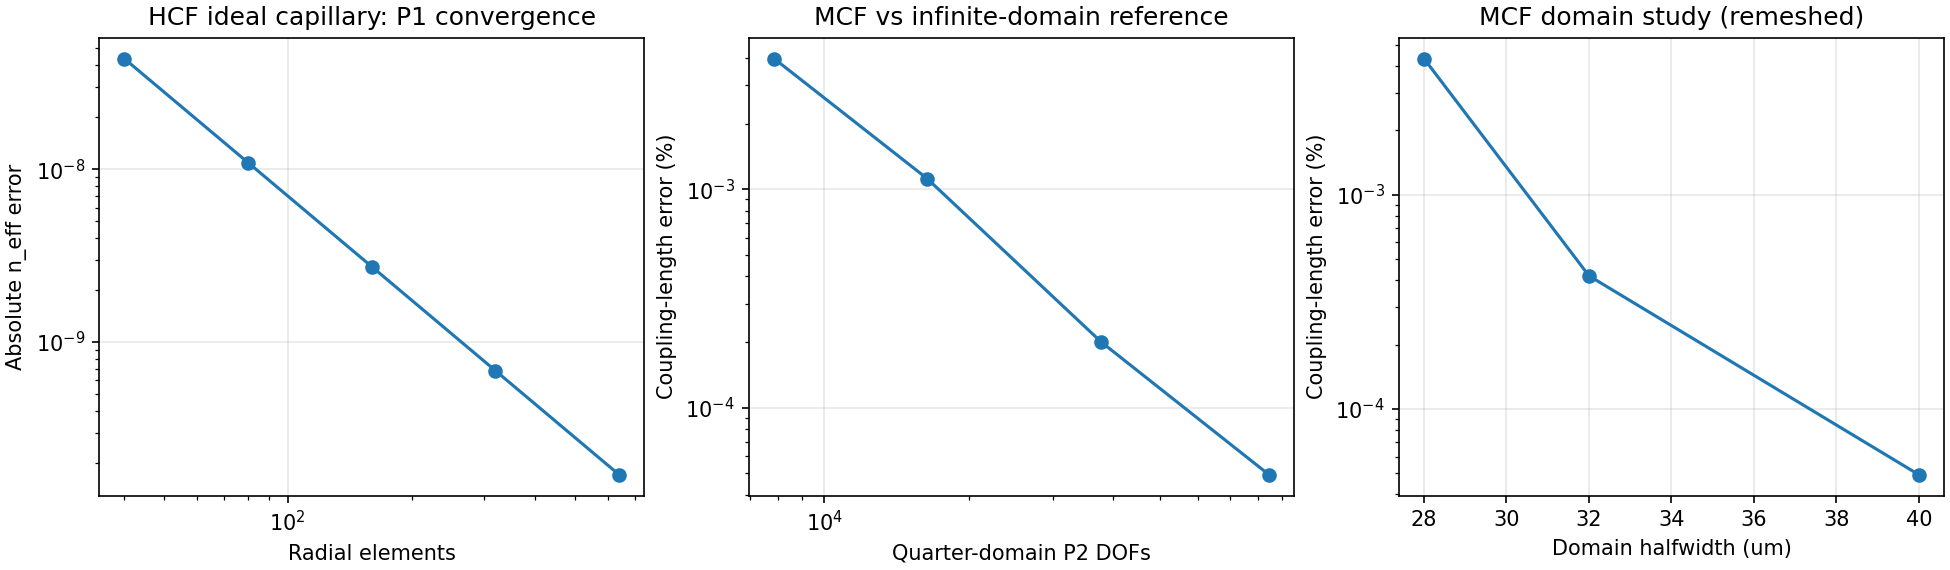

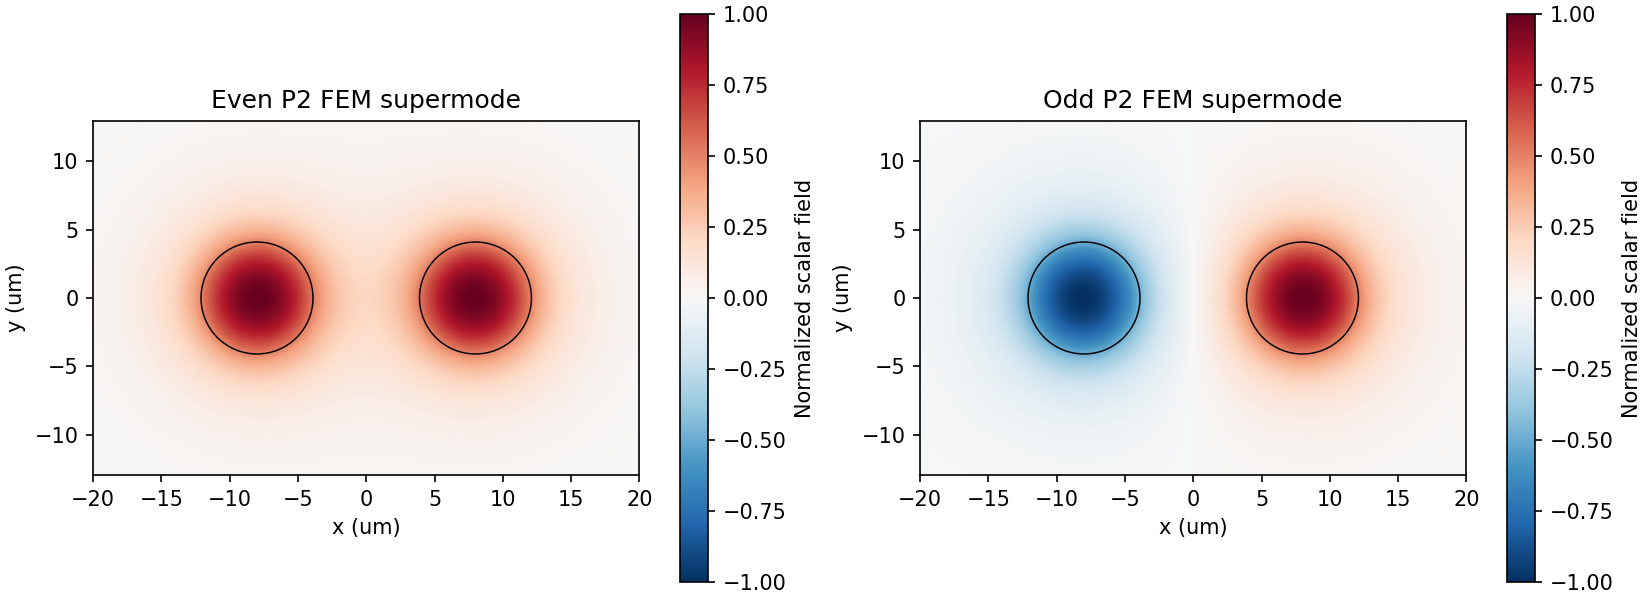

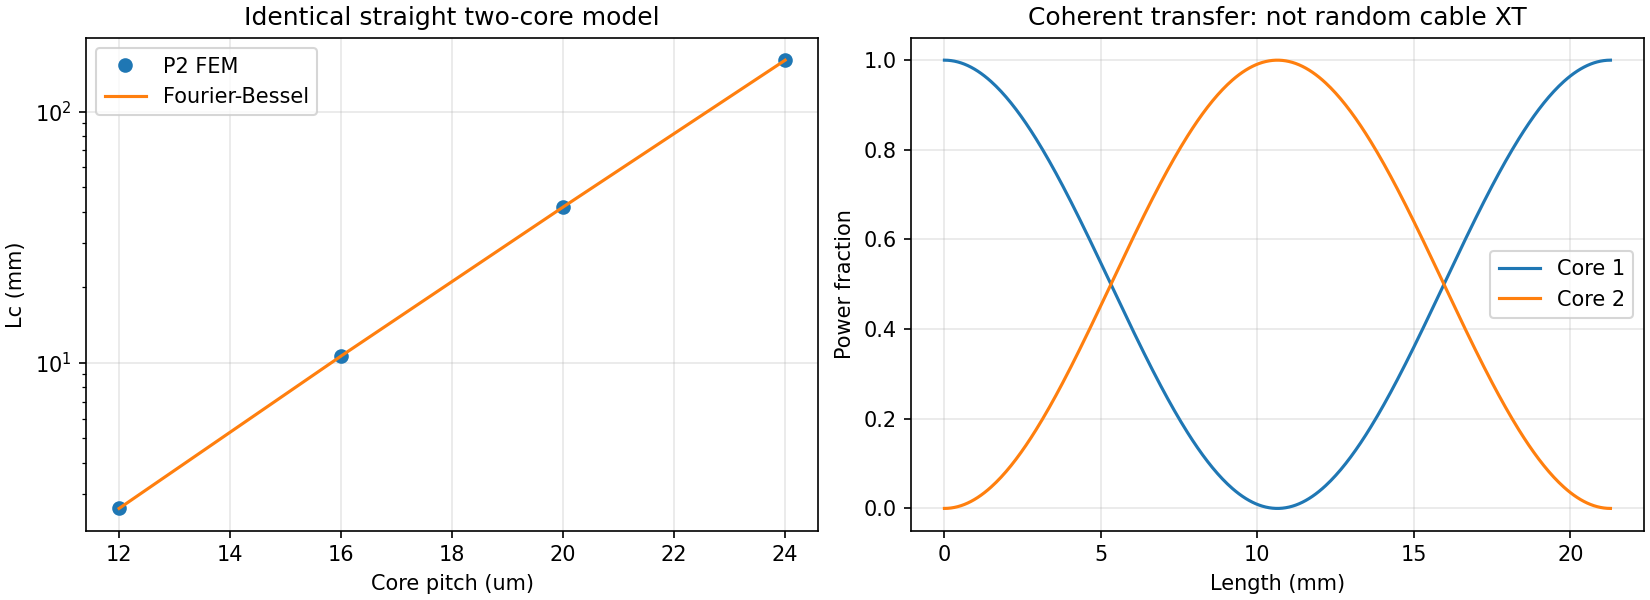

In [6]:
for name in ['01_convergence.png','02_mcf_supermodes.png','03_coupling.png']:
    display(Image(filename=str(OUTPUT/name)))

## 한계와 오차 원인

HCF 메시 오차는 방사형 P1 이산화에서 발생합니다. 유리벽·반공진·PML·구속 손실은 모델에 없습니다. 실물 HCF 대비 오차율은 미확인입니다.

MCF 잔여 오차는 FEM 공간/기하 근사와 외곽 경계에서 발생합니다. 기존 Cartesian P1은 재료 경계 분류도 변합니다. 원통함수 기준에도 전개 차수 절단·근 찾기 오차가 있으므로 차수와 각도 샘플 수를 검사합니다. 메시·영역·기준 해 수렴을 함께 봐야 합니다.

전력 전달은 동일 코어의 두 모드에 대한 무손실 모델입니다. z=Lc에서 P2=1이며 비팅 주기는 2Lc입니다. 실제 광섬유의 랜덤 누화(dB/km), 굽힘, 편광, 제조 편차를 포함하지 않습니다.

문헌: [Marcatili & Schmeltzer (1964)](https://doi.org/10.1002/j.1538-7305.1964.tb04108.x), [White et al. (2002)](https://doi.org/10.1364/JOSAB.19.002322). 이번 스칼라 코드는 이 논문들의 전체 벡터 모델을 구현하거나 실험 표를 재현한 것은 아닙니다.

In [7]:
import zipfile
PACKAGE=OUTPUT/'M8_HCF_MCF_Results.zip'
with zipfile.ZipFile(PACKAGE,'w',zipfile.ZIP_DEFLATED) as z:
    for path in sorted(OUTPUT.iterdir()):
        if path.is_file() and path!=PACKAGE:z.write(path,path.name)
print('결과 ZIP:',PACKAGE)
try:
    from google.colab import files
    files.download(str(PACKAGE))
except ImportError:
    print('로컬 실행에서는 출력 디렉터리에서 ZIP을 확인하십시오.')

결과 ZIP: /tmp/m8_hcf_mcf_xexa6bna/M8_HCF_MCF_Results.zip
로컬 실행에서는 출력 디렉터리에서 ZIP을 확인하십시오.
